# Task B Client Demo Notebook: 7-Day GSTD 5 Alert

This notebook is the client-facing demo version of the final Task B workflow. It shows the main early-warning framing, the key model results, and a live rerun of the recommended forward-time holdout test.

The goal is to demonstrate how the model can flag Stage 1 crop records that are likely to enter **GSTD 5 within the next 7 days**. The demo is intentionally shorter than the full technical notebook, but it stays aligned with the final Task B deliverable.

## Analysis Roadmap

1. Load the final validated dataset and rebuild the Task B target.
2. Explain the candidate Task B model options used in the final project.
3. Show the baseline Client-6 model under grouped validation by `RUNNO`.
4. Summarize the forward-time holdout results from the locked technical notebook.
5. Rerun the recommended model live on a future-year holdout split.
6. Convert model scores into alert thresholds.
7. Show example future-year alert scores.
8. Compare higher-recall, balanced, and higher-precision operating styles.
9. Visualize threshold behavior with confusion matrices.
10. Close with the final client takeaway and pipeline flow.

## 1. Data Loading and Task B Setup

In [1]:
# ============================================================
# SECTION 1: LOAD DATA FOR TASK B
# Build the 7-day GSTD 5 alert target
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from IPython.display import display

# Load the final validated dataset
from pathlib import Path

# We try a few common locations so the demo can run either from the handoff root
# or from inside the demo materials folder.
DATA_CANDIDATES = [
    Path("final_validated_dataset.csv"),
    Path("../02_Data/final_validated_dataset.csv"),
    Path("02_Data/final_validated_dataset.csv"),
]

DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find final_validated_dataset.csv. "
        "Place it beside this notebook or inside the 02_Data folder."
    )

print(f"Loading dataset from: {DATA_PATH}")
df_b = pd.read_csv(DATA_PATH).copy()

# Sort within each run so the 7-day future window is built correctly
if "DATE" in df_b.columns:
    df_b["DATE"] = pd.to_datetime(df_b["DATE"], errors="coerce")

sort_cols = [c for c in ["RUNNO", "DATE", "DAP"] if c in df_b.columns]
if sort_cols:
    df_b = df_b.sort_values(sort_cols).reset_index(drop=True)

# Keep only rows where the current growth stage is known
df_b = df_b[df_b["GSTD"].notna()].copy()

# Build the Task B target.
# A row is positive if the crop enters GSTD 5 within the next 7 days.
# Rows already at GSTD 5 are not counted as new upcoming transitions.
target_col_b = "y_enter5_7"
group_col_b = "RUNNO"

df_b[target_col_b] = 0

for runno, run_df in df_b.groupby(group_col_b):
    idx = run_df.index.tolist()
    gstd_vals = run_df["GSTD"].values

    for i in range(len(idx)):
        current_stage = gstd_vals[i]

        if current_stage == 5:
            df_b.loc[idx[i], target_col_b] = 0
            continue

        future_window = gstd_vals[i+1:i+8]
        df_b.loc[idx[i], target_col_b] = int(5 in future_window)

# Audit which current stages generate positives
stage_alert_audit_df = (
    df_b.groupby("GSTD")[target_col_b]
    .agg(
        Rows="count",
        Positive_Alerts="sum",
        Positive_Rate="mean"
    )
    .reset_index()
)

stage_alert_audit_df["Rows"] = stage_alert_audit_df["Rows"].astype(int)
stage_alert_audit_df["Positive_Alerts"] = stage_alert_audit_df["Positive_Alerts"].astype(int)
stage_alert_audit_df["Positive_Rate"] = stage_alert_audit_df["Positive_Rate"].round(4)

positive_stage_values = sorted(
    df_b.loc[df_b[target_col_b] == 1, "GSTD"].dropna().unique().tolist()
)

# Define the modeling subsets
all_taskb_df = df_b.copy()
at_risk_df = df_b[df_b["GSTD"].isin([1, 3])].copy()
stage1_df = df_b[df_b["GSTD"] == 1].copy()
stage3_df = df_b[df_b["GSTD"] == 3].copy()

# Main Task B modeling frame:
# Stage 1 subset only
model_df_b = stage1_df.copy()

# Exclude identifiers and direct time shortcuts
# Keep GSTD out of features because Stage 1 is fixed in this modeling frame
exclude_cols_b = {
    target_col_b,
    "GSTD",
    "RUNNO",
    "TRTNO",
    "TRTNA",
    "DATE",
    "YEAR",
    "DOY",
    "DAS",
    "DAP",
    "WDATE"
}

numeric_cols_b = model_df_b.select_dtypes(include=[np.number]).columns.tolist()
feature_cols_b = [c for c in numeric_cols_b if c not in exclude_cols_b]

X_b = model_df_b[feature_cols_b].copy()
y_b = model_df_b[target_col_b].astype(int).copy()
groups_b = model_df_b[group_col_b].copy()

# Presentation-friendly summary tables
treatment_count_b = model_df_b["TRTNO"].nunique() if "TRTNO" in model_df_b.columns else np.nan

setup_summary_b_df = pd.DataFrame({
    "Metric": [
        "Full validated rows",
        "Current stages producing positives",
        "At-risk subset rows (GSTD 1 or 3)",
        "Stage 1 modeling rows",
        "Stage 3 rows",
        "Stage 1 positive class rate",
        "Unique runs in Stage 1 frame",
        "Unique treatments in Stage 1 frame",
        "Feature count (Stage 1 full-signal frame)"
    ],
    "Value": [
        f"{len(df_b):,}",
        ", ".join(map(str, positive_stage_values)),
        f"{len(at_risk_df):,}",
        f"{len(stage1_df):,}",
        f"{len(stage3_df):,}",
        f"{y_b.mean():.4f}",
        f"{model_df_b['RUNNO'].nunique():,}",
        f"{treatment_count_b:,}" if pd.notna(treatment_count_b) else "N/A",
        len(feature_cols_b)
    ]
})

stage1_target_dist_b_df = pd.DataFrame({
    "Class": [0, 1],
    "Count": [
        int((y_b == 0).sum()),
        int((y_b == 1).sum())
    ],
    "Proportion": [
        round((y_b == 0).mean(), 4),
        round((y_b == 1).mean(), 4)
    ]
})

setup_summary_b_style = (
    setup_summary_b_df.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=["Value"], **{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

stage_alert_audit_style = (
    stage_alert_audit_df.style
    .hide(axis="index")
    .format({
        "Rows": "{:,}",
        "Positive_Alerts": "{:,}",
        "Positive_Rate": "{:.4f}"
    })
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

stage1_target_dist_b_style = (
    stage1_target_dist_b_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Task B Setup Summary")
display(setup_summary_b_style)

print("Task B Stage Audit")
display(stage_alert_audit_style)

print("Task B Stage 1 Target Distribution")
display(stage1_target_dist_b_style)

Loading dataset from: final_validated_dataset.csv
Task B Setup Summary


Metric,Value
Full validated rows,"135,240"
Current stages producing positives,"1, 3"
At-risk subset rows (GSTD 1 or 3),"11,011"
Stage 1 modeling rows,"6,164"
Stage 3 rows,"4,847"
Stage 1 positive class rate,0.3266
Unique runs in Stage 1 frame,980
Unique treatments in Stage 1 frame,35
Feature count (Stage 1 full-signal frame),131


Task B Stage Audit


GSTD,Rows,Positive_Alerts,Positive_Rate
0,"41,261",0,0.0000
1,"6,164","2,013",0.3266
3,"4,847","4,847",1.0000
5,"34,613",0,0.0000
7,"14,700",0,0.0000
8,"33,655",0,0.0000


Task B Stage 1 Target Distribution


Class,Count,Proportion
0,4151,0.673400
1,2013,0.326600


### Dataset Interpretation

The Task B target audit shows that positive 7-day GSTD 5 alerts arise only from **current GSTD 1 and 3** in this dataset. In addition, **Stage 3 is effectively deterministic** under this label structure, meaning it does not represent the main predictive challenge.

For that reason, the core Task B modeling problem is framed as a **Stage 1 early-warning task**: among observations currently at GSTD 1, which ones will enter GSTD 5 within the next 7 days?

This Stage 1 framing is more faithful to the original Task B notebook and more operationally meaningful, because it focuses the alert model on the part of the process where prediction is still necessary.

## 2. Candidate Task B Models

For the client demo, we do not rerun every model family from the technical notebook. Instead, we summarize the main candidate feature sets that were tested and then rerun the recommended model live.

| Candidate model | Feature framing | Why it matters |
|---|---|---|
| Client-6 baseline | Six client-feasible daily variables only | Simple operational baseline |
| Client-6 + LAID | Client-6 plus LAID/LAI-equivalent information | Tests the client-requested LAI/LAID signal |
| Client-6 + time-series | Client-6 plus lag, rolling, and change features | Captures short-term crop/weather dynamics |
| Client-6 + LAID + time-series | Time-series features plus LAID | Tests whether LAID adds value after temporal features are included |

The locked technical notebook showed that the strongest practical framing is the **Client-6 + time-series LightGBM model**, with **Client-6 + LAID + time-series** as a small optional extension when LAID is reliably available.

## 3. Baseline Client-6 Model Results

In [2]:
# ============================================================
# SECTION 3: CLIENT-6 BASELINE
# GroupKFold by RUNNO on the Stage 1 early-warning frame
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)
from lightgbm import LGBMClassifier
from IPython.display import display

# These are the six client-feasible variables we agreed to test first
client6_features_b = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD"]

missing_client6_b = [c for c in client6_features_b if c not in model_df_b.columns]
if missing_client6_b:
    raise ValueError(f"These client-feasible columns are missing from model_df_b: {missing_client6_b}")

X_client6_b = model_df_b[client6_features_b].copy()
y_client6_b = model_df_b[target_col_b].astype(int).copy()
groups_client6_b = model_df_b[group_col_b].copy()

# Small summary table for the demo
client6_b_summary_df = pd.DataFrame({
    "Metric": [
        "Modeling frame",
        "Feature set",
        "Number of features",
        "Positive class rate"
    ],
    "Value": [
        "Stage 1 early-warning subset",
        ", ".join(client6_features_b),
        len(client6_features_b),
        f"{y_client6_b.mean():.4f}"
    ]
})

client6_b_summary_style = (
    client6_b_summary_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Client 6 Feature Summary")
display(client6_b_summary_style)

# GroupKFold by RUNNO
n_splits = 5
gkf_client6_b = GroupKFold(n_splits=n_splits)

oof_proba_client6_b = np.zeros(len(y_client6_b), dtype=float)
fold_rows_client6_b = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_client6_b.split(X_client6_b, y_client6_b, groups=groups_client6_b), start=1
):
    X_train, X_valid = X_client6_b.iloc[train_idx], X_client6_b.iloc[valid_idx]
    y_train, y_valid = y_client6_b.iloc[train_idx], y_client6_b.iloc[valid_idx]

    model_client6_b = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="binary",
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_client6_b.fit(X_train, y_train)
    valid_proba = model_client6_b.predict_proba(X_valid)[:, 1]

    oof_proba_client6_b[valid_idx] = valid_proba

    fold_ap = average_precision_score(y_valid, valid_proba)
    fold_roc = roc_auc_score(y_valid, valid_proba)

    fold_rows_client6_b.append({
        "Fold": fold,
        "Training rows": len(train_idx),
        "Validation rows": len(valid_idx),
        "Average Precision": fold_ap,
        "ROC-AUC": fold_roc
    })

client6_b_results = pd.DataFrame(fold_rows_client6_b)

# Mean CV summary
metric_cols = ["Average Precision", "ROC-AUC"]
client6_b_mean_metrics = client6_b_results[metric_cols].mean()

client6_b_summary_metrics_df = pd.DataFrame({
    "Metric": ["Average Precision (PR-AUC)", "ROC-AUC"],
    "Value": [
        round(client6_b_mean_metrics["Average Precision"], 4),
        round(client6_b_mean_metrics["ROC-AUC"], 4)
    ]
})

client6_b_metrics_style = (
    client6_b_summary_metrics_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Client 6 Baseline: Mean Cross-Validation Performance")
display(client6_b_metrics_style)

# Overall OOF results
overall_ap_client6_b = average_precision_score(y_client6_b, oof_proba_client6_b)
overall_roc_client6_b = roc_auc_score(y_client6_b, oof_proba_client6_b)

client6_b_oof_summary_df = pd.DataFrame({
    "Metric": ["OOF Average Precision (PR-AUC)", "OOF ROC-AUC"],
    "Value": [
        round(overall_ap_client6_b, 4),
        round(overall_roc_client6_b, 4)
    ]
})

client6_b_oof_style = (
    client6_b_oof_summary_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Overall Out-of-Fold Performance")
display(client6_b_oof_style)

# Save these outputs so later cells can reuse them
precision_b, recall_b, thresholds_b = precision_recall_curve(y_client6_b, oof_proba_client6_b)

pr_curve_df_b = pd.DataFrame({
    "Recall": recall_b[:-1],
    "Precision": precision_b[:-1],
    "Threshold": thresholds_b
})

taskB_client6_results = client6_b_results.copy()
taskB_client6_pr_curve = pr_curve_df_b.copy()
taskB_client6_oof_proba = oof_proba_client6_b.copy()

Client 6 Feature Summary


Metric,Value
Modeling frame,Stage 1 early-warning subset
Feature set,"TMND, PREC, SRAD, TMXD, TAVD, NURTD"
Number of features,6
Positive class rate,0.3266


Client 6 Baseline: Mean Cross-Validation Performance


Metric,Value
Average Precision (PR-AUC),0.999600
ROC-AUC,0.999800


Overall Out-of-Fold Performance


Metric,Value
OOF Average Precision (PR-AUC),0.999600
OOF ROC-AUC,0.999800


### Client 6 Baseline Interpretation

Within the **Stage 1 early-warning frame**, the Client 6 baseline already performs extremely well under grouped validation on unseen runs, with near-perfect **Average Precision (PR-AUC)** and **ROC-AUC**.

This shows that Task B is highly learnable once it is framed correctly as a Stage 1 warning problem. However, because the leading models all perform strongly under GroupKFold, this evaluation is best treated as a confirmation that the signal exists rather than as the main basis for model selection.

For the remainder of Task B, the more important question is **future-year robustness**. That is why the next key comparison focuses on **forward time holdout**, which provides the strongest deployment-style test of whether the alert model remains reliable on later years.

## 4. Forward Time Holdout: Key Deployment Test

### 4A. Time Holdout Comparison Across Main Candidate Models

In [3]:
# ============================================================
# SECTION 4: FORWARD TIME HOLDOUT COMPARISON
# Final candidate model summary from the locked technical notebook
# ============================================================

import pandas as pd
from IPython.display import display

# Forward time holdout split summary
# Split used in the locked final Task B technical notebook
split_summary_b = pd.DataFrame({
    "Metric": [
        "Training years",
        "Test years",
        "Training rows",
        "Test rows",
        "Training positive rate",
        "Test positive rate"
    ],
    "Value": [
        "2023-2044",
        "2045-2050",
        "4,853",
        "1,311",
        "0.3315",
        "0.3082"
    ]
})

split_summary_style = (
    split_summary_b.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Forward Time Holdout Split Summary")
display(split_summary_style)

# Final technical-notebook results used for the compact demo summary
time_holdout_comparison_b = pd.DataFrame([
    {
        "Model": "1. Strict Stage 1 Benchmark",
        "Feature Count": 57,
        "Average Precision (PR-AUC)": 0.8484,
        "ROC-AUC": 0.9141
    },
    {
        "Model": "2. Client-Feasible Raw",
        "Feature Count": 6,
        "Average Precision (PR-AUC)": 0.3468,
        "ROC-AUC": 0.5386
    },
    {
        "Model": "3. Client-Feasible + LAID",
        "Feature Count": 7,
        "Average Precision (PR-AUC)": 0.5449,
        "ROC-AUC": 0.6902
    },
    {
        "Model": "4. Client-Feasible Time-Series",
        "Feature Count": 46,
        "Average Precision (PR-AUC)": 0.8722,
        "ROC-AUC": 0.9438
    },
    {
        "Model": "5. Client-Feasible + LAID + Time-Series",
        "Feature Count": 52,
        "Average Precision (PR-AUC)": 0.8761,
        "ROC-AUC": 0.9451
    }
])

raw_pr = 0.3468
raw_roc = 0.5386
ts_pr = 0.8722
ts_roc = 0.9438

time_holdout_comparison_b["PR-AUC Gain vs Raw Client"] = (
    time_holdout_comparison_b["Average Precision (PR-AUC)"] - raw_pr
).round(4)

time_holdout_comparison_b["ROC-AUC Gain vs Raw Client"] = (
    time_holdout_comparison_b["ROC-AUC"] - raw_roc
).round(4)

time_holdout_comparison_b["PR-AUC Gain vs Client TS"] = (
    time_holdout_comparison_b["Average Precision (PR-AUC)"] - ts_pr
).round(4)

time_holdout_comparison_b["ROC-AUC Gain vs Client TS"] = (
    time_holdout_comparison_b["ROC-AUC"] - ts_roc
).round(4)

time_holdout_style_b = (
    time_holdout_comparison_b.style
    .hide(axis="index")
    .format({
        "Average Precision (PR-AUC)": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC Gain vs Raw Client": "{:.4f}",
        "ROC-AUC Gain vs Raw Client": "{:.4f}",
        "PR-AUC Gain vs Client TS": "{:.4f}",
        "ROC-AUC Gain vs Client TS": "{:.4f}"
    })
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Forward Time Holdout Comparison")
display(time_holdout_style_b)

# Compact presenter summary
time_holdout_summary_b = time_holdout_comparison_b[[
    "Model",
    "Average Precision (PR-AUC)",
    "ROC-AUC",
    "PR-AUC Gain vs Raw Client",
    "PR-AUC Gain vs Client TS"
]].copy()

time_holdout_summary_style_b = (
    time_holdout_summary_b.style
    .hide(axis="index")
    .format({
        "Average Precision (PR-AUC)": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC Gain vs Raw Client": "{:.4f}",
        "PR-AUC Gain vs Client TS": "{:.4f}"
    })
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Forward Time Holdout Presenter Summary")
display(time_holdout_summary_style_b)

# Save
taskB_time_holdout_results = time_holdout_comparison_b.copy()
taskB_time_holdout_split_summary = split_summary_b.copy()
taskB_time_holdout_presenter_summary = time_holdout_summary_b.copy()

Forward Time Holdout Split Summary


Metric,Value
Training years,2023-2044
Test years,2045-2050
Training rows,"4,853"
Test rows,"1,311"
Training positive rate,0.3315
Test positive rate,0.3082


Forward Time Holdout Comparison


Model,Feature Count,Average Precision (PR-AUC),ROC-AUC,PR-AUC Gain vs Raw Client,ROC-AUC Gain vs Raw Client,PR-AUC Gain vs Client TS,ROC-AUC Gain vs Client TS
1. Strict Stage 1 Benchmark,57,0.8484,0.9141,0.5016,0.3755,-0.0238,-0.0297
2. Client-Feasible Raw,6,0.3468,0.5386,0.0000,0.0000,-0.5254,-0.4052
3. Client-Feasible + LAID,7,0.5449,0.6902,0.1981,0.1516,-0.3273,-0.2536
4. Client-Feasible Time-Series,46,0.8722,0.9438,0.5254,0.4052,0.0000,0.0000
5. Client-Feasible + LAID + Time-Series,52,0.8761,0.9451,0.5293,0.4065,0.0039,0.0013


Forward Time Holdout Presenter Summary


Model,Average Precision (PR-AUC),ROC-AUC,PR-AUC Gain vs Raw Client,PR-AUC Gain vs Client TS
1. Strict Stage 1 Benchmark,0.8484,0.9141,0.5016,-0.0238
2. Client-Feasible Raw,0.3468,0.5386,0.0000,-0.5254
3. Client-Feasible + LAID,0.5449,0.6902,0.1981,-0.3273
4. Client-Feasible Time-Series,0.8722,0.9438,0.5254,0.0000
5. Client-Feasible + LAID + Time-Series,0.8761,0.9451,0.5293,0.0039


### Forward Time Holdout Interpretation

This is the most important evaluation in Task B because it tests whether the alert model remains reliable when trained on earlier years and applied to later years.

The time holdout results show a very different picture from GroupKFold. Although all candidate models perform extremely well under grouped validation, the **raw client-feasible model** drops sharply on future years, with **PR-AUC = 0.3468** and **ROC-AUC = 0.5386**. This shows that same-day client-approved measurements alone are not robust enough for deployment under temporal shift.

Adding **LAID** improves future-year performance substantially, increasing PR-AUC to **0.5449**. This is important because LAID was part of the client proposal, and the results show that it does provide useful crop-state information in Task B. However, the largest improvement comes from adding **time-series features**. The **client-feasible TS model** reaches **PR-AUC = 0.8722** and **ROC-AUC = 0.9438**, slightly outperforming even the **strict Stage 1 benchmark** on forward time holdout.

The strongest overall feature-rich feasible model is **Client-Feasible + LAID + Time-Series**, which reaches **PR-AUC = 0.8761** and **ROC-AUC = 0.9451**. However, the gain over the TS-only feasible model is very small. The main Task B conclusion is therefore that **time-series structure is the dominant driver of deployment robustness**, while **LAID provides a meaningful but secondary improvement**, especially relative to the raw client-feasible model.

### LAID Sensitivity Summary

The Task B results show that **LAID is useful, but not the main reason the alert becomes robust**.

Compared with the raw client-feasible model, adding **LAID** alone improves forward time holdout performance meaningfully. However, the largest improvement comes from adding **time-series features**. Once temporal context is already available, adding LAID provides only a **small additional lift**.

This means LAID can be presented as a **helpful optional enhancement** in Task B, while the primary recommendation remains centered on **time-series engineering from client-feasible variables**.

## 5. Live Demo: Rerun the Recommended Model

### 5A. Rebuild the Recommended Task B Modeling Frame

In [4]:
# ============================================================
# SECTION 5A: REBUILD RECOMMENDED TASK B MODELING FRAME
# Stage 1 early-warning with client-feasible time-series features
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# Rebuild the Stage 1 modeling frame from the setup above
demo_b_df = model_df_b.copy()

if "DATE" in demo_b_df.columns:
    demo_b_df["DATE"] = pd.to_datetime(demo_b_df["DATE"], errors="coerce")

demo_b_df = demo_b_df.sort_values(["RUNNO", "DATE"]).reset_index(drop=True)

# Client-feasible variables used in the recommended demo model
client6_demo_b = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD"]

missing_demo_b = [c for c in client6_demo_b if c not in demo_b_df.columns]
if missing_demo_b:
    raise ValueError(f"Missing Task B demo columns: {missing_demo_b}")

# Add the temperature range feature used in the final Task B workflow
demo_b_df["TEMP_RANGE"] = demo_b_df["TMXD"] - demo_b_df["TMND"]

# Build the same style of lag, difference, and rolling features used in the final workflow
base_ts_demo_b = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD", "TEMP_RANGE"]

for col in base_ts_demo_b:
    demo_b_df[f"{col}_lag1"] = demo_b_df.groupby("RUNNO")[col].shift(1)
    demo_b_df[f"{col}_lag3"] = demo_b_df.groupby("RUNNO")[col].shift(3)
    demo_b_df[f"{col}_lag7"] = demo_b_df.groupby("RUNNO")[col].shift(7)

    demo_b_df[f"{col}_diff1"] = demo_b_df.groupby("RUNNO")[col].diff(1)

    demo_b_df[f"{col}_rollmean3"] = (
        demo_b_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
    )
    demo_b_df[f"{col}_rollmean7"] = (
        demo_b_df.groupby("RUNNO")[col]
        .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).mean())
    )

demo_b_df["PREC_rollsum3"] = (
    demo_b_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)
demo_b_df["PREC_rollsum7"] = (
    demo_b_df.groupby("RUNNO")["PREC"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

demo_b_df["NURTD_rollsum3"] = (
    demo_b_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).sum())
)
demo_b_df["NURTD_rollsum7"] = (
    demo_b_df.groupby("RUNNO")["NURTD"]
    .transform(lambda s: s.shift(1).rolling(window=7, min_periods=1).sum())
)

# Final Task B demo feature set
# Match the original client-feasible TS logic only
demo_b_feature_cols = []

# base variables
demo_b_feature_cols += client6_demo_b
demo_b_feature_cols += ["TEMP_RANGE"]

# lag / diff / rolling mean features
for col in base_ts_demo_b:
    demo_b_feature_cols += [
        f"{col}_lag1",
        f"{col}_lag3",
        f"{col}_lag7",
        f"{col}_diff1",
        f"{col}_rollmean3",
        f"{col}_rollmean7",
    ]

# extra rolling sums from original notebook
demo_b_feature_cols += [
    "PREC_rollsum3",
    "PREC_rollsum7",
    "NURTD_rollsum3",
    "NURTD_rollsum7"
]

# keep only columns that actually exist
demo_b_feature_cols = [c for c in demo_b_feature_cols if c in demo_b_df.columns]

# drop all-NaN columns to match original style
all_nan_demo_b = demo_b_df[demo_b_feature_cols].isna().all()
demo_b_feature_cols = [c for c in demo_b_feature_cols if not all_nan_demo_b[c]]

X_demo_b = demo_b_df[demo_b_feature_cols].copy()
y_demo_b = demo_b_df[target_col_b].astype(int).copy()
groups_demo_b = demo_b_df[group_col_b].copy()

# Presentation-friendly summary
demo_b_summary_df = pd.DataFrame({
    "Metric": [
        "Modeling frame",
        "Base client variables",
        "Derived variable",
        "Temporal features added",
        "Final feature count",
        "Modeling rows",
        "Positive class rate"
    ],
    "Value": [
        "Stage 1 early-warning subset",
        ", ".join(client6_demo_b),
        "TEMP_RANGE = TMXD - TMND",
        "lag1, lag3, lag7, diff1, rollmean3, rollmean7, PREC/NURTD rollsum3/7",
        len(demo_b_feature_cols),
        f"{len(demo_b_df):,}",
        f"{y_demo_b.mean():.4f}"
    ]
})

demo_b_summary_style = (
    demo_b_summary_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Task B Live Demo Feature Set Summary")
display(demo_b_summary_style)

preview_cols_b = [c for c in ["RUNNO", "DATE", "GSTD"] if c in demo_b_df.columns]
preview_cols_b += client6_demo_b + [target_col_b]
preview_df_b = demo_b_df[preview_cols_b].head(8).copy()

if "DATE" in preview_df_b.columns:
    preview_df_b["DATE"] = pd.to_datetime(preview_df_b["DATE"]).dt.date

round_cols_b = [c for c in preview_df_b.columns if c not in ["RUNNO", "DATE", "GSTD", target_col_b]]
preview_df_b[round_cols_b] = preview_df_b[round_cols_b].round(2)

preview_style_b = (
    preview_df_b.style
    .hide(axis="index")
    .format({col: "{:.2f}" for col in round_cols_b})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Preview of Stage 1 Rows Used for Live Demo")
display(preview_style_b)

Task B Live Demo Feature Set Summary


Metric,Value
Modeling frame,Stage 1 early-warning subset
Base client variables,"TMND, PREC, SRAD, TMXD, TAVD, NURTD"
Derived variable,TEMP_RANGE = TMXD - TMND
Temporal features added,"lag1, lag3, lag7, diff1, rollmean3, rollmean7, PREC/NURTD rollsum3/7"
Final feature count,46
Modeling rows,"6,164"
Positive class rate,0.3266


Preview of Stage 1 Rows Used for Live Demo


RUNNO,DATE,GSTD,TMND,PREC,SRAD,TMXD,TAVD,NURTD,y_enter5_7
1,2023-06-17,1,17.30,497.00,27.80,35.80,26.70,0.00,0
1,2023-06-18,1,22.70,501.00,26.20,37.00,30.00,0.00,0
1,2023-06-19,1,24.80,504.00,23.60,36.50,30.70,0.00,0
1,2023-06-20,1,25.20,505.00,24.50,36.50,30.90,0.00,0
1,2023-06-21,1,26.20,511.00,22.80,36.20,31.30,0.00,1
1,2023-06-22,1,26.30,513.00,27.00,37.50,32.00,0.00,1
2,2024-06-15,1,22.40,503.00,17.60,27.30,24.90,0.00,0
2,2024-06-16,1,22.40,524.00,12.80,26.10,24.30,0.00,0


### 5B. Rerun the Forward Time Holdout Live

In [10]:
# ============================================================
# SECTION 5B: LIVE FORWARD TIME HOLDOUT RERUN
# Train and score the recommended model on future years
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier

# Build the live demo evaluation frame
live_time_df = demo_b_df[["RUNNO", "DATE", target_col_b] + demo_b_feature_cols].copy()
live_time_df["DATE"] = pd.to_datetime(live_time_df["DATE"], errors="coerce")
live_time_df["YEAR_ONLY"] = live_time_df["DATE"].dt.year

live_time_df = live_time_df.dropna(subset=["YEAR_ONLY"]).copy()
live_time_df["YEAR_ONLY"] = live_time_df["YEAR_ONLY"].astype(int)
live_time_df[target_col_b] = live_time_df[target_col_b].astype(int)

print("=" * 72)
print("Step 1: Stage 1 early-warning frame rebuilt")
print(f"Rows available: {len(live_time_df):,}")
print(f"Feature count : {len(demo_b_feature_cols)}")
print(f"Positive rate : {live_time_df[target_col_b].mean():.4f}")

# Split by time: train on earlier years and test on future years
train_mask_live = live_time_df["YEAR_ONLY"] <= 2044
test_mask_live = live_time_df["YEAR_ONLY"] >= 2045

train_live_df = live_time_df.loc[train_mask_live].copy()
test_live_df = live_time_df.loc[test_mask_live].copy()

print("=" * 72)
print("Step 2: Forward time holdout split created")
print("Training years : 2023-2044")
print("Test years     : 2045-2050")
print(f"Training rows  : {len(train_live_df):,}")
print(f"Test rows      : {len(test_live_df):,}")
print(f"Train pos rate : {train_live_df[target_col_b].mean():.4f}")
print(f"Test pos rate  : {test_live_df[target_col_b].mean():.4f}")

# Prepare train and test matrices
X_train_live = train_live_df[demo_b_feature_cols].copy()
y_train_live = train_live_df[target_col_b].copy()

X_test_live = test_live_df[demo_b_feature_cols].copy()
y_test_live = test_live_df[target_col_b].copy()

train_medians_live = X_train_live.median(numeric_only=True)
X_train_live = X_train_live.fillna(train_medians_live)
X_test_live = X_test_live.fillna(train_medians_live)

print("=" * 72)
print("Step 3: Train/test matrices prepared")
print(f"X_train shape  : {X_train_live.shape}")
print(f"X_test shape   : {X_test_live.shape}")

# Fit model
live_time_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("=" * 72)
print("Step 4: Fitting client-feasible time-series model...")
live_time_model.fit(X_train_live, y_train_live)

# Score the held-out future years
live_test_proba = live_time_model.predict_proba(X_test_live)[:, 1]

live_ap = average_precision_score(y_test_live, live_test_proba)
live_roc = roc_auc_score(y_test_live, live_test_proba)

print("=" * 72)
print("Step 5: Held-out future-year scoring complete")
print(f"Average Precision (PR-AUC): {live_ap:.4f}")
print(f"ROC-AUC                   : {live_roc:.4f}")

# Save outputs for the alert and threshold sections
taskB_live_time_model = live_time_model
taskB_live_time_test_df = test_live_df.copy()
taskB_live_time_y = y_test_live.copy()
taskB_live_time_proba = pd.Series(live_test_proba, index=test_live_df.index)
taskB_live_time_ap = live_ap
taskB_live_time_roc = live_roc

# Keep these aliases because the threshold cells use the same names as the
# final technical notebook.
taskB_time_client_ts_y = taskB_live_time_y.copy()
taskB_time_client_ts_proba = taskB_live_time_proba.copy()

Step 1: Stage 1 early-warning frame rebuilt
Rows available: 6,164
Feature count : 46
Positive rate : 0.3266
Step 2: Forward time holdout split created
Training years : 2023-2044
Test years     : 2045-2050
Training rows  : 4,853
Test rows      : 1,311
Train pos rate : 0.3315
Test pos rate  : 0.3082
Step 3: Train/test matrices prepared
X_train shape  : (4853, 46)
X_test shape   : (1311, 46)
Step 4: Fitting client-feasible time-series model...
Step 5: Held-out future-year scoring complete
Average Precision (PR-AUC): 0.8722
ROC-AUC                   : 0.9438


## 6. Turning Model Scores Into an Operational Alert

### 6A. Threshold Tradeoff for the Recommended Alert Model

In [6]:
# ============================================================
# SECTION 6A: THRESHOLD TRADEOFF FOR RECOMMENDED ALERT MODEL
# Use the live model scores to compare alert thresholds
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve
from IPython.display import display

# Use probabilities from the live forward-time holdout rerun above.
# These are the same recommended client-feasible TS model scores used for the alert demo.
# These aliases are created by the live rerun cell. They match the naming used in the
# full technical notebook, which makes the threshold logic easier to compare.
y_time = pd.Series(taskB_time_client_ts_y).reset_index(drop=True).astype(int)
proba_time = pd.Series(taskB_time_client_ts_proba).reset_index(drop=True)

precision_ts, recall_ts, thresholds_ts = precision_recall_curve(y_time, proba_time)

threshold_df = pd.DataFrame({
    "Threshold": thresholds_ts,
    "Precision": precision_ts[:-1],
    "Recall": recall_ts[:-1]
})

# Add F1 for easier interpretation
threshold_df["F1"] = (
    2 * threshold_df["Precision"] * threshold_df["Recall"] /
    (threshold_df["Precision"] + threshold_df["Recall"]).replace(0, np.nan)
)
threshold_df["F1"] = threshold_df["F1"].fillna(0)

# Select a small set of representative operating points
# based on recall targets
target_recalls = [0.95, 0.90, 0.85, 0.80, 0.70, 0.60]

rows = []
for target in target_recalls:
    eligible = threshold_df[threshold_df["Recall"] >= target].copy()
    if not eligible.empty:
        row = eligible.sort_values("Threshold", ascending=False).iloc[0].copy()
        row["Operating Point"] = f"Recall ≥ {target:.2f}"
        rows.append(row)

# Best F1 point
best_f1_row = threshold_df.sort_values("F1", ascending=False).iloc[0].copy()
best_f1_row["Operating Point"] = "Best F1"
rows.append(best_f1_row)

threshold_summary = pd.DataFrame(rows)
threshold_summary = threshold_summary[[
    "Operating Point", "Threshold", "Precision", "Recall", "F1"
]].copy()

threshold_summary[["Threshold", "Precision", "Recall", "F1"]] = threshold_summary[
    ["Threshold", "Precision", "Recall", "F1"]
].round(4)

threshold_summary_style = (
    threshold_summary.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Threshold Tradeoff Summary for Client-Feasible Time-Series Model")
display(threshold_summary_style)

# Fixed-threshold operating points for easier presentation
fixed_thresholds = [0.25, 0.50, 0.75, 0.90, 0.99]

fixed_rows = []
for t in fixed_thresholds:
    nearest_idx = (threshold_df["Threshold"] - t).abs().idxmin()
    row = threshold_df.loc[nearest_idx].copy()
    row["Target Threshold"] = t
    fixed_rows.append(row)

threshold_preview = pd.DataFrame(fixed_rows).drop_duplicates()
threshold_preview = threshold_preview[[
    "Target Threshold", "Threshold", "Precision", "Recall", "F1"
]].copy()

threshold_preview = threshold_preview.rename(columns={
    "Threshold": "Nearest Available Threshold"
})

threshold_preview[[
    "Target Threshold", "Nearest Available Threshold", "Precision", "Recall", "F1"
]] = threshold_preview[[
    "Target Threshold", "Nearest Available Threshold", "Precision", "Recall", "F1"
]].round(4)

threshold_preview_style = (
    threshold_preview.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Fixed Threshold Operating Points")
display(threshold_preview_style)

# Save
taskB_threshold_summary = threshold_summary.copy()
taskB_threshold_preview = threshold_preview.copy()
taskB_threshold_curve = threshold_df.copy()

Threshold Tradeoff Summary for Client-Feasible Time-Series Model


Operating Point,Threshold,Precision,Recall,F1
Recall ≥ 0.95,0.000000,0.612900,0.967800,0.750500
Recall ≥ 0.90,0.000300,0.678400,0.903500,0.774900
Recall ≥ 0.85,0.786900,0.760300,0.863900,0.808800
Recall ≥ 0.80,0.999800,0.865100,0.809400,0.836300
Recall ≥ 0.70,0.999900,0.870900,0.717800,0.787000
Recall ≥ 0.60,1.000000,0.886500,0.618800,0.728900
Best F1,0.998400,0.843800,0.829200,0.836500


Fixed Threshold Operating Points


Target Threshold,Nearest Available Threshold,Precision,Recall,F1
0.250000,0.246300,0.742600,0.863900,0.798600
0.500000,0.472200,0.755400,0.863900,0.806000
0.750000,0.786900,0.760300,0.863900,0.808800
0.900000,0.893500,0.769800,0.844100,0.805200
0.990000,0.989500,0.827200,0.829200,0.828200


### Threshold Interpretation

This table shows how the recommended Task B alert model can be turned into an operational decision rule.

Lower thresholds produce **higher recall**, which means the model catches more upcoming GSTD 5 transitions, but they also reduce precision and therefore generate more false alerts. Higher thresholds increase **precision**, but at the cost of missing more true transitions.

The recall-based operating points are useful when the client wants to think directly in terms of coverage, while the fixed-threshold examples make it easier to see how the alert would behave at practical score cutoffs. The purpose of this section is not to force a single universal threshold, but to make the operational tradeoff clear.

## 7. Show Example Future-Year Alert Scores

In [7]:
# ============================================================
# SECTION 7: SHOW EXAMPLE FUTURE-YEAR ALERT SCORES
# Sample held-out predictions from the live forward-time holdout
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# Choose an operating threshold
# Use the Best F1 threshold from the earlier threshold section
best_f1_row = taskB_threshold_summary[taskB_threshold_summary["Operating Point"] == "Best F1"].iloc[0]
alert_threshold_b = float(best_f1_row["Threshold"])

# Build held-out prediction table
future_alert_df = taskB_live_time_test_df.copy()

future_alert_df["y_true"] = taskB_live_time_y.values
future_alert_df["alert_score"] = taskB_live_time_proba.values
future_alert_df["predicted_alert"] = (future_alert_df["alert_score"] >= alert_threshold_b).astype(int)

future_alert_df["alert_correct"] = np.where(
    future_alert_df["y_true"] == future_alert_df["predicted_alert"],
    "Yes",
    "No"
)

# Choose display columns
display_cols_b = [c for c in ["RUNNO", "DATE"] if c in future_alert_df.columns]
display_cols_b += ["y_true", "alert_score", "predicted_alert", "alert_correct"]

future_alert_display = future_alert_df[display_cols_b].copy()

if "DATE" in future_alert_display.columns:
    future_alert_display["DATE"] = pd.to_datetime(future_alert_display["DATE"]).dt.date

future_alert_display["alert_score"] = future_alert_display["alert_score"].round(4)

# Show examples
correct_alerts = future_alert_display[future_alert_display["alert_correct"] == "Yes"].head(6)
incorrect_alerts = future_alert_display[future_alert_display["alert_correct"] == "No"].head(6)

print(f"Operating threshold used for live demo: {alert_threshold_b:.4f}")

print("Sample Correct Future-Year Alert Decisions")
display(correct_alerts.style.hide(axis="index"))

print("Sample Incorrect Future-Year Alert Decisions")
display(incorrect_alerts.style.hide(axis="index"))

# Alert summary
alert_summary_df = pd.DataFrame({
    "Metric": [
        "Held-out future-year rows scored",
        "Threshold used",
        "Predicted alerts",
        "True upcoming transitions",
        "Correct alert decisions",
        "Incorrect alert decisions"
    ],
    "Value": [
        f"{len(future_alert_display):,}",
        f"{alert_threshold_b:.4f}",
        f"{future_alert_display['predicted_alert'].sum():,}",
        f"{future_alert_display['y_true'].sum():,}",
        f"{(future_alert_display['alert_correct'] == 'Yes').sum():,}",
        f"{(future_alert_display['alert_correct'] == 'No').sum():,}"
    ]
})

alert_summary_style = (
    alert_summary_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Future-Year Alert Summary")
display(alert_summary_style)

# Save
taskB_live_future_alerts = future_alert_display.copy()

Operating threshold used for live demo: 0.9984
Sample Correct Future-Year Alert Decisions


RUNNO,DATE,y_true,alert_score,predicted_alert,alert_correct
23,2045-06-14,0,0.000000,0,Yes
23,2045-06-15,0,0.000000,0,Yes
23,2045-06-16,0,0.000000,0,Yes
23,2045-06-18,1,1.000000,1,Yes
24,2046-06-12,0,0.000000,0,Yes
24,2046-06-13,0,0.000000,0,Yes


Sample Incorrect Future-Year Alert Decisions


RUNNO,DATE,y_true,alert_score,predicted_alert,alert_correct
23,2045-06-17,1,0.000700,0,No
24,2046-06-17,1,0.000000,0,No
28,2050-06-16,0,1.000000,1,No
51,2045-06-17,1,0.000700,0,No
52,2046-06-17,1,0.000000,0,No
56,2050-06-16,0,1.000000,1,No


Future-Year Alert Summary


Metric,Value
Held-out future-year rows scored,"1,311"
Threshold used,0.9984
Predicted alerts,389
True upcoming transitions,404
Correct alert decisions,"1,172"
Incorrect alert decisions,139


### Live Alert Example Interpretation

These examples show how the recommended Task B model behaves on truly held-out future-year data once a threshold is applied.

Using the **Best F1 threshold (0.9984)** produces a relatively selective alert rule: the model issues alerts only when its confidence is very high, which helps reduce unnecessary false alerts. At the same time, some true upcoming transitions are missed, which is the expected tradeoff when using a more conservative threshold.

This reinforces the practical Task B message: the model can produce a usable early-warning signal, but the final operating threshold should depend on whether the client wants to prioritize **higher precision** or **higher recall**.

## 8. Example Operating Styles

In [8]:
# ============================================================
# SECTION 8: EXAMPLE OPERATING STYLES
# Higher recall vs balanced vs higher precision
# ============================================================

import pandas as pd
from IPython.display import display

# Pull the threshold summary table created earlier
operating_styles_df = taskB_threshold_summary.copy()

# Map to cleaner presentation labels
style_rows = []

# Higher recall example
recall_row = operating_styles_df[operating_styles_df["Operating Point"] == "Recall ≥ 0.90"].iloc[0].copy()
recall_row["Style"] = "Higher Recall"

# Balanced example
balanced_row = operating_styles_df[operating_styles_df["Operating Point"] == "Best F1"].iloc[0].copy()
balanced_row["Style"] = "Balanced"

# Higher precision example
precision_row = operating_styles_df[operating_styles_df["Operating Point"] == "Recall ≥ 0.80"].iloc[0].copy()
precision_row["Style"] = "Higher Precision"

style_rows.extend([recall_row, balanced_row, precision_row])

operating_styles_summary = pd.DataFrame(style_rows)[[
    "Style", "Threshold", "Precision", "Recall", "F1"
]].copy()

operating_styles_summary[["Threshold", "Precision", "Recall", "F1"]] = operating_styles_summary[
    ["Threshold", "Precision", "Recall", "F1"]
].round(4)

operating_styles_style = (
    operating_styles_summary.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Example Threshold Operating Styles")
display(operating_styles_style)

# Save
taskB_operating_styles = operating_styles_summary.copy()

Example Threshold Operating Styles


Style,Threshold,Precision,Recall,F1
Higher Recall,0.000300,0.678400,0.903500,0.774900
Balanced,0.998400,0.843800,0.829200,0.836500
Higher Precision,0.999800,0.865100,0.809400,0.836300


## 9. Comparing Alert Behavior Across Threshold Choices

This section compares the same Task B model under three threshold choices using the held-out future-year scores from the live rerun.

Side-by-Side Threshold Comparison


Metric,Higher Recall,Balanced,Higher Precision
Threshold,0.0003,0.9984,0.9998
Precision,0.6863,0.8406,0.8651
Recall,0.8936,0.8094,0.8094
F1,0.7763,0.8247,0.8363
Predicted alerts,526,389,378
True upcoming transitions,404,404,404
True negatives,742,845,856
False positives,165,62,51
False negatives,43,77,77
True positives,361,327,327


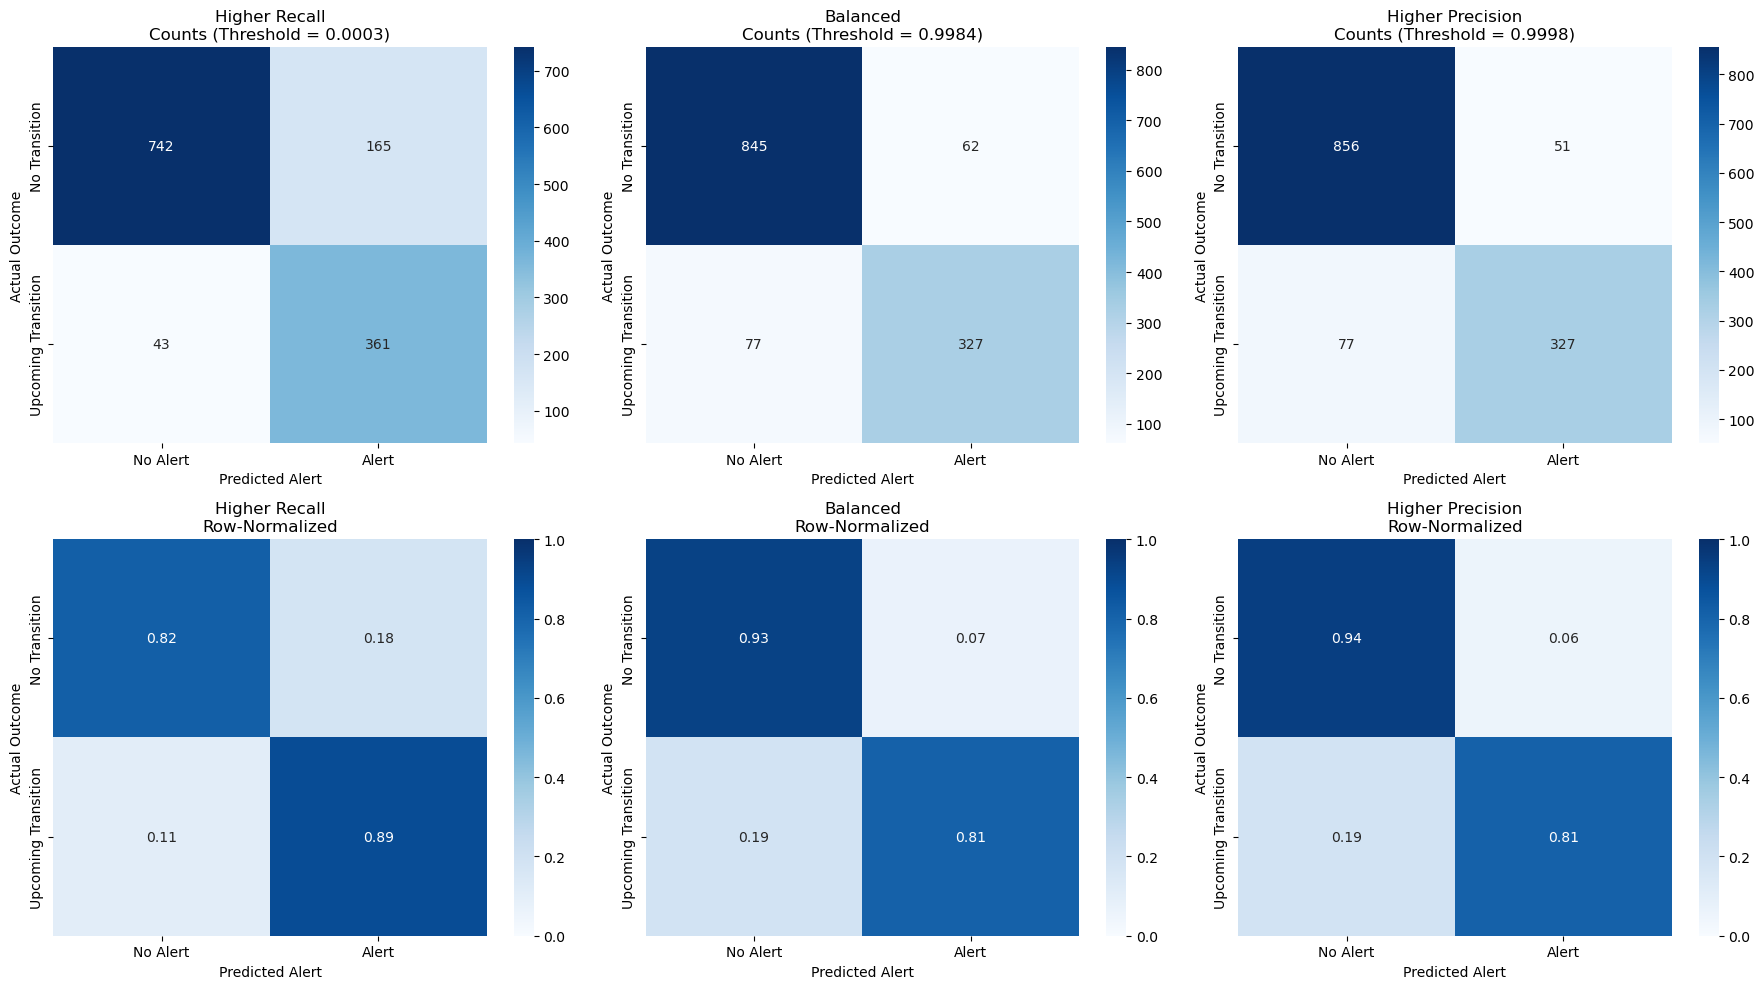

In [9]:
# ============================================================
# SECTION 9: COMPARE ALERT BEHAVIOR ACROSS THRESHOLDS
# Rounded summary and confusion matrices for each threshold style
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from IPython.display import display

# Source data
y_true_cmp = pd.Series(taskB_time_client_ts_y).reset_index(drop=True).astype(int)
y_score_cmp = pd.Series(taskB_time_client_ts_proba).reset_index(drop=True)

# Pull the three operating styles
styles_to_compare = ["Higher Recall", "Balanced", "Higher Precision"]

style_results = {}
style_confusions = {}

for style_name in styles_to_compare:
    row = taskB_operating_styles[taskB_operating_styles["Style"] == style_name].iloc[0]
    threshold = float(row["Threshold"])

    y_pred = (y_score_cmp >= threshold).astype(int)

    cm_counts = confusion_matrix(y_true_cmp, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm_counts.ravel()

    cm_row_norm = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)

    precision_val = precision_score(y_true_cmp, y_pred, zero_division=0)
    recall_val = recall_score(y_true_cmp, y_pred, zero_division=0)
    f1_val = f1_score(y_true_cmp, y_pred, zero_division=0)

    style_results[style_name] = {
        "Threshold": threshold,
        "Precision": precision_val,
        "Recall": recall_val,
        "F1": f1_val,
        "Predicted alerts": int(y_pred.sum()),
        "True upcoming transitions": int(y_true_cmp.sum()),
        "True negatives": int(tn),
        "False positives": int(fp),
        "False negatives": int(fn),
        "True positives": int(tp),
        "Correct decisions": int((y_pred == y_true_cmp).sum()),
        "Incorrect decisions": int((y_pred != y_true_cmp).sum())
    }

    style_confusions[style_name] = {
        "threshold": threshold,
        "counts": cm_counts,
        "row_norm": cm_row_norm
    }

# Build side-by-side comparison table
comparison_rows = [
    "Threshold",
    "Precision",
    "Recall",
    "F1",
    "Predicted alerts",
    "True upcoming transitions",
    "True negatives",
    "False positives",
    "False negatives",
    "True positives",
    "Correct decisions",
    "Incorrect decisions"
]

threshold_comparison_df = pd.DataFrame(
    {style: [style_results[style][row] for row in comparison_rows] for style in styles_to_compare},
    index=comparison_rows
).reset_index()

threshold_comparison_df = threshold_comparison_df.rename(columns={"index": "Metric"})

# Rounded display copy
threshold_comparison_display_df = threshold_comparison_df.copy()

decimal_metrics = {"Threshold", "Precision", "Recall", "F1"}
count_metrics = {
    "Predicted alerts",
    "True upcoming transitions",
    "True negatives",
    "False positives",
    "False negatives",
    "True positives",
    "Correct decisions",
    "Incorrect decisions"
}

for style in styles_to_compare:
    threshold_comparison_display_df[style] = threshold_comparison_display_df.apply(
        lambda row: (
            f"{float(row[style]):.4f}" if row["Metric"] in decimal_metrics
            else f"{int(round(float(row[style]))):,}" if row["Metric"] in count_metrics
            else row[style]
        ),
        axis=1
    )

threshold_comparison_style = (
    threshold_comparison_display_df.style
    .hide(axis="index")
    .set_properties(subset=["Metric"], **{"text-align": "left"})
    .set_properties(subset=styles_to_compare, **{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]}
    ])
)

print("Side-by-Side Threshold Comparison")
display(threshold_comparison_style)

# Confusion matrices for each threshold style
# Top row: counts
# Bottom row: row-normalized
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col_idx, style_name in enumerate(styles_to_compare):
    threshold = style_confusions[style_name]["threshold"]
    cm_counts = style_confusions[style_name]["counts"]
    cm_row_norm = style_confusions[style_name]["row_norm"]

    # Count matrix
    sns.heatmap(
        cm_counts,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        ax=axes[0, col_idx],
        xticklabels=["No Alert", "Alert"],
        yticklabels=["No Transition", "Upcoming Transition"]
    )
    axes[0, col_idx].set_title(f"{style_name}\nCounts (Threshold = {threshold:.4f})")
    axes[0, col_idx].set_xlabel("Predicted Alert")
    axes[0, col_idx].set_ylabel("Actual Outcome")

    # Row-normalized matrix
    sns.heatmap(
        cm_row_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        cbar=True,
        vmin=0,
        vmax=1,
        ax=axes[1, col_idx],
        xticklabels=["No Alert", "Alert"],
        yticklabels=["No Transition", "Upcoming Transition"]
    )
    axes[1, col_idx].set_title(f"{style_name}\nRow-Normalized")
    axes[1, col_idx].set_xlabel("Predicted Alert")
    axes[1, col_idx].set_ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

# Save outputs for later use
taskB_threshold_side_by_side = threshold_comparison_df.copy()
taskB_threshold_side_by_side_display = threshold_comparison_display_df.copy()
taskB_threshold_confusions = style_confusions.copy()

### 9A. Threshold Confusion Matrix Interpretation

These confusion matrices show how the same Task B alert model behaves under three different operating styles: **Higher Recall**, **Balanced**, and **Higher Precision**.

The count matrices show the absolute number of:
- correct non-alerts,
- false alerts,
- missed upcoming transitions, and
- correctly identified upcoming transitions.

The row-normalized matrices make it easier to compare the tradeoff across the two actual outcome groups.

Together, these views reinforce the threshold story visually:
- **Higher Recall** catches more true upcoming transitions but also increases false alerts,
- **Higher Precision** reduces false alerts but misses more true transitions, and
- **Balanced** provides a middle ground between those two extremes.

This helps translate the model from a score-producing classifier into an operational alert system with clearly different threshold behaviors.

## 10. Task B Final Takeaway

The final Task B demo supports the same conclusion as the locked technical notebook: the best client-facing alert model is a **Stage 1 early-warning LightGBM model** using the client-feasible variables with time-series feature engineering.

The live rerun is intentionally faster than GroupKFold and treatment-holdout testing because it trains one forward-time holdout model instead of repeatedly fitting models across folds or held-out treatments. It is still doing the actual training and scoring work for the recommended demo model.

For handoff, the main operational message is that threshold selection should be treated as a business decision. A higher-recall setting catches more upcoming GSTD 5 transitions, while a higher-precision setting reduces false alerts.

### 10A. Pipeline Flow Diagram

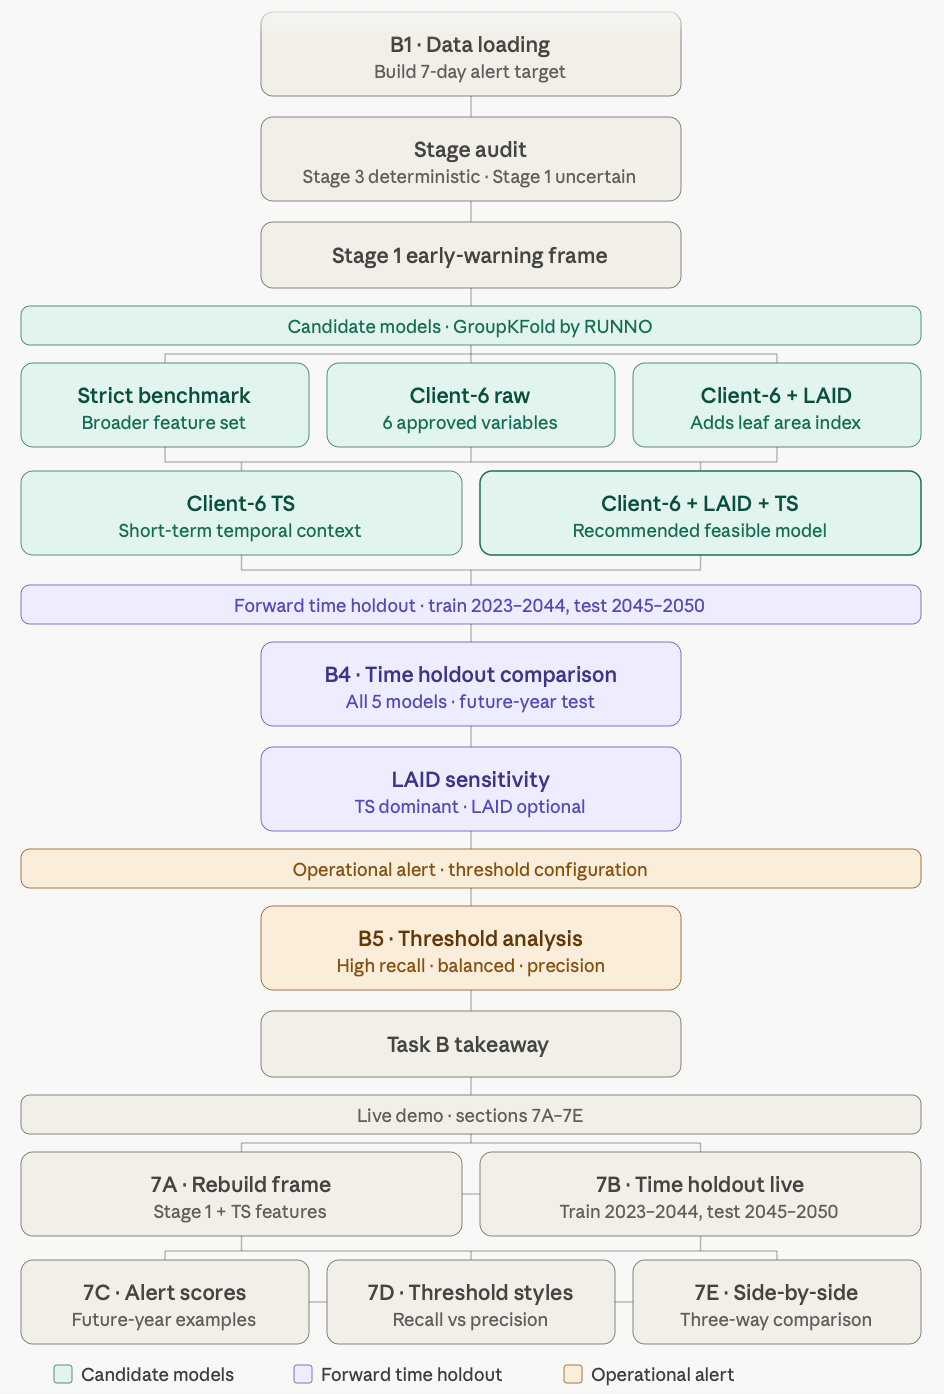